# Base ECLYPSE vs ECLYPSE+NET: the stress suite

This notebook analyses the results of `main.py --suite stress`. Every scenario is
simulated twice, with base ECLYPSE and with ECLYPSE+NET, on a static network: the same
Barabási–Albert topology, the same placement and the same flows, with **no update
policies**. Two parameters vary:

- **network size**: the number of routers;
- **load**: the packets generated per step in total, split among the flows.

With a static scenario, the execution time depends only on the size of the network and
on the load, so the cost of the packet-level model can be read as a function of both.
The suite also measures two methods of ECLYPSE inside the `enact` phase: the placement
check (`PlacementManager.audit`) and the computation of a path
(`Infrastructure._compute_path`). Base ECLYPSE caches the paths of the application
links and, on a static network, never needs to recompute them; ECLYPSE+NET writes the
`latency` of the links at every step, and every such write invalidates the cache.

`main.py --suite stress` saves one row per simulation in `results.csv` and one row per
step in `steps.csv`, by default in `~/eclypse-sim/eclypse_comparison_stress/`.

## Setup

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D

RESULTS = Path(os.environ.get(
    "ECLYPSE_COMPARISON_STRESS_RESULTS",
    Path.home() / "eclypse-sim" / "eclypse_comparison_stress",
))
df = pd.read_csv(RESULTS / "results.csv")
steps = pd.read_csv(RESULTS / "steps.csv")

SIZES = sorted(int(s) for s in df["routers"].unique())
LOADS = sorted(int(n) for n in df["packets_per_step"].unique())
MODES = {
    "base": {"label": "ECLYPSE", "color": "#2a78d6", "marker": "o"},
    "net": {"label": "ECLYPSE+NET", "color": "#eb6834", "marker": "s"},
}
# One color per network size: light = small
SIZE_COLORS = dict(zip(SIZES, ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b", "#06203f"], strict=False))

# Chart style: light surface, recessive axes and grid
SURFACE, TEXT, TEXT_MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": TEXT_MUTED,
    "axes.titlecolor": TEXT,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": TEXT_MUTED,
    "ytick.color": TEXT_MUTED,
    "legend.frameon": False,
    "legend.labelcolor": TEXT,
    "font.size": 10,
})

# Mean over the seeds of each mode, size and load
KEY = ["mode", "routers", "packets_per_step"]
mean = df.groupby(KEY).mean(numeric_only=True).reset_index()

print(f"{len(df)} simulations: {df.groupby('mode').size().to_dict()}")
print(f"topologies: {sorted(df['topology'].unique())}, routers: {SIZES}, "
      f"packets per step: {LOADS}, seeds: {sorted(df['seed'].unique().tolist())}")
print("update policies:", sorted(df["policies"].unique().tolist()))

40 simulations: {'base': 20, 'net': 20}
topologies: ['scale_free'], routers: [64, 128, 256, 512], packets per step: [10, 100, 500, 1000, 2000], seeds: [3997]
update policies: [False]


## 1. The scenarios

Size of the networks and, for ECLYPSE+NET, the traffic simulated: packets generated,
hops, drops and packets still travelling at the end. Without policies the two modes
must end with the same graphs, which the last line checks.

In [2]:
net = mean[mean["mode"] == "net"].set_index(["routers", "packets_per_step"])
print(net[["n_hosts", "n_links", "n_flows", "generated", "hops", "dropped",
           "in_transit_at_end"]].round(1).to_string())

END = ["end_links", "end_bandwidth_sum", "end_rate_sum", "end_size_sum"]
paired = df.pivot_table(index=["topology", "routers", "packets_per_step", "seed"],
                        columns="mode", values=END)
same = np.all([np.isclose(paired[(c, "base")], paired[(c, "net")]) for c in END], axis=0)
print(f"\nScenarios with the same final state in both modes: {int(same.sum())} of {len(same)}")

                          n_hosts  n_links  n_flows  generated       hops  dropped  in_transit_at_end
routers packets_per_step                                                                             
64      10                   64.0    188.0    100.0     1014.0     4670.0      0.0               40.0
        100                  64.0    188.0    100.0    10076.0    45996.0      0.0              407.0
        500                  64.0    188.0    100.0    49846.0   229178.0      0.0             1823.0
        1000                 64.0    188.0    100.0   100354.0   460367.0      0.0             3685.0
        2000                 64.0    188.0    100.0   200655.0   892755.0  11190.0             7210.0
128     10                  128.0    380.0    100.0     1014.0     4834.0      0.0               42.0
        100                 128.0    380.0    100.0    10076.0    48468.0      0.0              436.0
        500                 128.0    380.0    100.0    49846.0   240689.0      0.0

## 2. Execution time and load

Wall-clock time of the whole simulation (`sim.start()` to the end of `sim.wait()`)
against the packets generated per step. Solid lines are ECLYPSE+NET, dashed lines base
ECLYPSE on the same network, which has no packets and therefore does not depend on the
load.

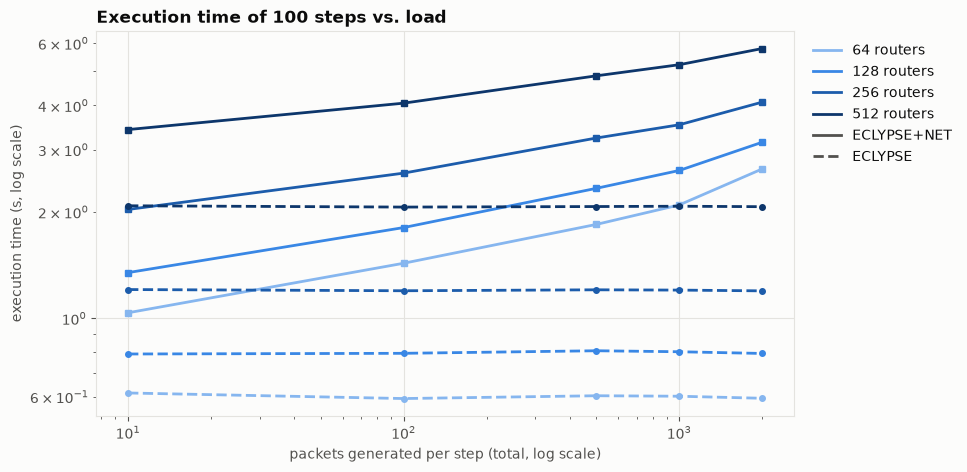

ECLYPSE+NET / ECLYPSE, execution time:
routers            64    128   256   512
packets_per_step                        
10                1.69  1.70  1.68  1.64
100               2.41  2.27  2.15  1.97
500               3.05  2.88  2.69  2.34
1000              3.48  3.26  2.93  2.51
2000              4.45  3.96  3.42  2.80


In [3]:
fig, ax = plt.subplots(figsize=(9, 5))
for size in SIZES:
    color = SIZE_COLORS[size]
    for mode, style in (("net", "-"), ("base", "--")):
        s = mean[(mean["mode"] == mode) & (mean["routers"] == size)]
        ax.plot(s["packets_per_step"], s["sim_time_s"], color=color, ls=style, lw=2,
                marker=MODES[mode]["marker"], ms=4)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("packets generated per step (total, log scale)")
ax.set_ylabel("execution time (s, log scale)")
ax.set_title(f"Execution time of {int(df['steps_run'].max())} steps vs. load", loc="left")
handles = [Line2D([], [], color=SIZE_COLORS[s], lw=2, label=f"{s} routers") for s in SIZES]
handles += [Line2D([], [], color=TEXT_MUTED, lw=2, label="ECLYPSE+NET"),
            Line2D([], [], color=TEXT_MUTED, lw=2, ls="--", label="ECLYPSE")]
ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

times = mean.pivot_table(index="packets_per_step", columns=["routers", "mode"],
                         values="sim_time_s")
overhead = pd.DataFrame({size: times[(size, "net")] / times[(size, "base")] for size in SIZES})
overhead.columns.name = "routers"
print("ECLYPSE+NET / ECLYPSE, execution time:")
print(overhead.round(2).to_string())

## 3. Where the time goes

Time per step spent in each phase, for the lightest and the heaviest load. The `enact`
phase is split into the path computations of ECLYPSE and the rest of the placement
check and enactment. `generation` and `routing` exist only in ECLYPSE+NET; `other` is
the rest of the simulation (scheduling of the events).

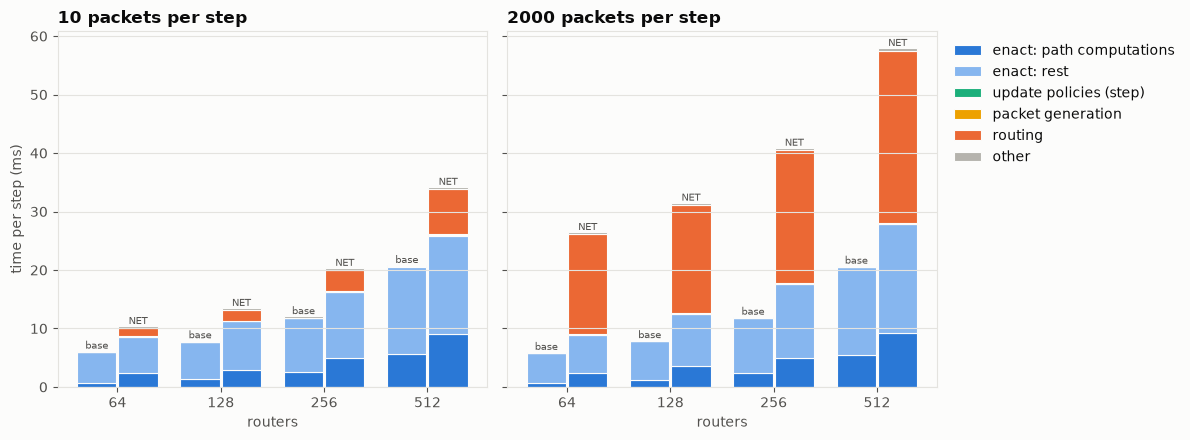

Share of the execution time (%):
                               enact: path computations  enact: rest  update policies (step)  packet generation  routing  other
mode routers packets_per_step                                                                                                  
base 64      10                                    10.7         86.9                     0.1                0.0      0.0    2.3
             2000                                  10.9         86.6                     0.1                0.0      0.0    2.4
     128     10                                    16.1         81.9                     0.1                0.0      0.0    2.0
             2000                                  16.0         82.0                     0.1                0.0      0.0    2.0
     256     10                                    20.5         77.9                     0.0                0.0      0.0    1.6
             2000                                  20.6         77.8   

In [4]:
PARTS = [
    ("path_time_s", "enact: path computations", "#2a78d6"),
    ("enact_rest_s", "enact: rest", "#86b6ef"),
    ("policies_time_s", "update policies (step)", "#1baf7a"),
    ("generation_time_s", "packet generation", "#eda100"),
    ("routing_time_s", "routing", "#eb6834"),
    ("other_time_s", "other", "#b5b3ad"),
]
mean["enact_rest_s"] = mean["enact_time_s"] - mean["path_time_s"]
for column, _, _ in PARTS:
    mean[column.replace("_s", "_ms_per_step")] = mean[column] / mean["steps_run"] * 1000

extremes = [min(LOADS), max(LOADS)]
fig, axes = plt.subplots(1, len(extremes), figsize=(6 * len(extremes), 4.5), sharey=True,
                         squeeze=False)
width = 0.38
for ax, load in zip(axes[0], extremes, strict=True):
    x = np.arange(len(SIZES))
    for offset, mode in ((-width / 2 - 0.01, "base"), (width / 2 + 0.01, "net")):
        rows = mean[(mean["mode"] == mode) & (mean["packets_per_step"] == load)].set_index("routers")
        bottom = np.zeros(len(SIZES))
        for column, label, color in PARTS:
            values = rows.loc[SIZES, column.replace("_s", "_ms_per_step")].to_numpy()
            ax.bar(x + offset, values, width, bottom=bottom, color=color,
                   edgecolor=SURFACE, linewidth=0.8, label=label if mode == "net" else None)
            bottom += values
        for xi, total in zip(x, bottom, strict=True):
            ax.text(xi + offset, total, "base" if mode == "base" else "NET",
                    ha="center", va="bottom", fontsize=7, color=TEXT_MUTED)
    ax.set_xticks(x, [str(s) for s in SIZES])
    ax.set_xlabel("routers")
    ax.set_title(f"{load} packets per step", loc="left")
    ax.grid(axis="x", visible=False)
axes[0, 0].set_ylabel("time per step (ms)")
axes[0, -1].legend(loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout()
plt.show()

share = mean[mean["packets_per_step"].isin(extremes)].set_index(KEY)
share = (100 * share[[c for c, _, _ in PARTS]].div(share["sim_time_s"], axis=0)).round(1)
share.columns = [label for _, label, _ in PARTS]
print("Share of the execution time (%):")
print(share.to_string())

## 4. Path computations of ECLYPSE

At every step ECLYPSE checks the placement: for each application link it retrieves the
path between the two services. Base ECLYPSE computes these paths at the first step and
then reuses them, since nothing changes. ECLYPSE+NET updates the `latency` of the links
it used at every step, and ECLYPSE discards all its cached paths whenever an attribute
of a link changes, so every check recomputes them. The routing of `Network` uses the
inverse of the bandwidth as cost, so these latency updates never change a path: the
recomputation is a cost of the integration between the extension and the framework,
not of the packet model.

Left: path computations per step, after the first step. Right: time spent computing
paths over the whole simulation, against the number of routers.

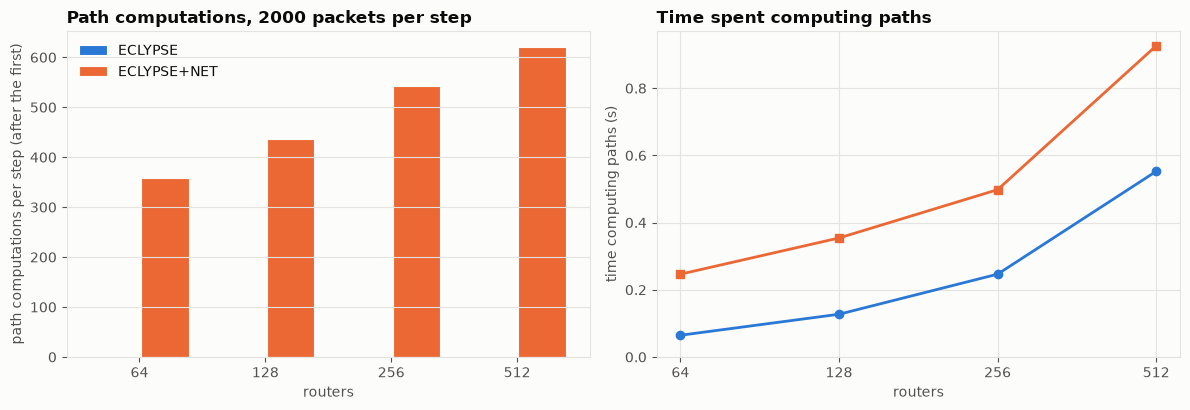

                               first step  per later step  path_calls  path_time_s  audit_time_s  paths / audit (%)
mode routers packets_per_step                                                                                      
base 64      2000                   340.0             0.0       340.0        0.065         0.577             11.190
     128     2000                   421.0             0.0       421.0        0.127         0.776             16.380
     256     2000                   524.0             0.0       524.0        0.246         1.171             21.047
     512     2000                   587.0             0.0       587.0        0.553         2.037             27.122
net  64      2000                   358.0           358.0     35800.0        0.246         0.885             27.843
     128     2000                   436.0           436.0     43600.0        0.354         1.241             28.541
     256     2000                   543.0           543.0     54300.0   

In [5]:
later = steps[steps["step"] > 1].groupby(KEY)["path_calls"].mean().reset_index()
first = steps[steps["step"] == 1].groupby(KEY)["path_calls"].mean().reset_index()

load = max(LOADS)
fig, (ax_calls, ax_time) = plt.subplots(1, 2, figsize=(12, 4.2))
x = np.arange(len(SIZES))
for offset, (mode, style) in zip((-0.2, 0.2), MODES.items(), strict=True):
    values = later[(later["mode"] == mode) & (later["packets_per_step"] == load)].set_index("routers")
    ax_calls.bar(x + offset, values.loc[SIZES, "path_calls"], 0.38, color=style["color"],
                 edgecolor=SURFACE, linewidth=0.8, label=style["label"])
    rows = mean[(mean["mode"] == mode) & (mean["packets_per_step"] == load)]
    ax_time.plot(rows["routers"], rows["path_time_s"], color=style["color"],
                 marker=style["marker"], lw=2, label=style["label"])
ax_calls.set_xticks(x, [str(s) for s in SIZES])
ax_calls.set_xlabel("routers")
ax_calls.set_ylabel("path computations per step (after the first)")
ax_calls.set_title(f"Path computations, {load} packets per step", loc="left")
ax_calls.grid(axis="x", visible=False)
ax_calls.legend(loc="upper left")
ax_time.set_xscale("log", base=2)
ax_time.set_xticks(SIZES, [str(s) for s in SIZES])
ax_time.minorticks_off()
ax_time.set_xlabel("routers")
ax_time.set_ylabel("time computing paths (s)")
ax_time.set_title("Time spent computing paths", loc="left")
ax_time.set_ylim(bottom=0)
fig.tight_layout()
plt.show()

table = pd.DataFrame({
    "first step": first.set_index(KEY)["path_calls"],
    "per later step": later.set_index(KEY)["path_calls"],
})
table = table.join(mean.set_index(KEY)[["path_calls", "path_time_s", "audit_time_s"]])
table["paths / audit (%)"] = 100 * table["path_time_s"] / table["audit_time_s"]
print(table[table.index.get_level_values("packets_per_step") == load].round(3).to_string())

## 5. Cost of the packet model

The routing time of the steps after the first, divided by the hops they simulate (the
first step also builds the forwarding tables of `Network`). Forwarding is vectorised
over all the packets of a step, so the fixed cost of a step is shared by more packets
as the load grows.

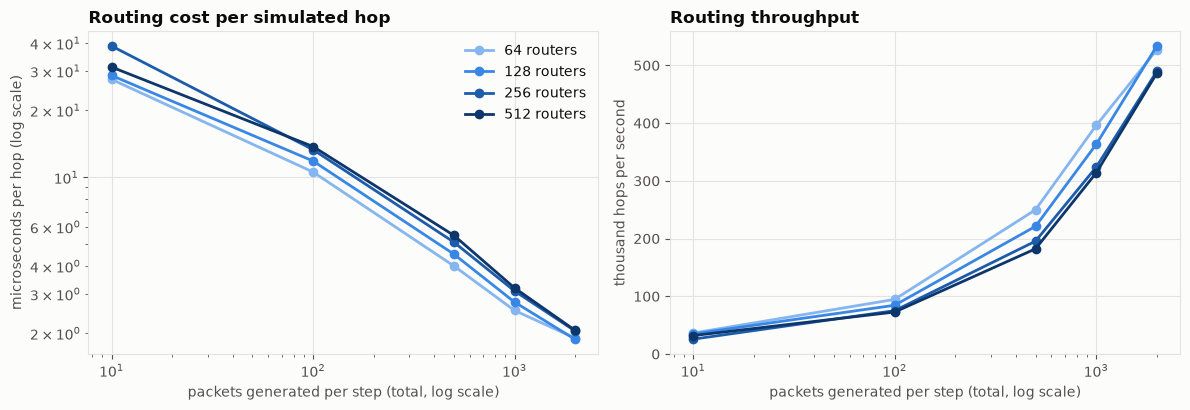

Routing time of the first step, which builds the forwarding tables (ms):
routers
64      14.62
128     43.90
256    157.16
512    599.12


In [6]:
net_steps = steps[(steps["mode"] == "net") & (steps["step"] > 1)]
cost = net_steps.groupby(["routers", "packets_per_step"])[["routing_s", "hops"]].sum()
cost["us_per_hop"] = 1e6 * cost["routing_s"] / cost["hops"]
cost["hops_per_s"] = cost["hops"] / cost["routing_s"]
cost = cost.reset_index()

fig, (ax_cost, ax_rate) = plt.subplots(1, 2, figsize=(12, 4.2))
for size in SIZES:
    s = cost[cost["routers"] == size]
    ax_cost.plot(s["packets_per_step"], s["us_per_hop"], color=SIZE_COLORS[size], marker="o",
                 lw=2, label=f"{size} routers")
    ax_rate.plot(s["packets_per_step"], s["hops_per_s"] / 1e3, color=SIZE_COLORS[size],
                 marker="o", lw=2, label=f"{size} routers")
for ax in (ax_cost, ax_rate):
    ax.set_xscale("log")
    ax.set_xlabel("packets generated per step (total, log scale)")
ax_cost.set_yscale("log")
ax_cost.set_ylabel("microseconds per hop (log scale)")
ax_cost.set_title("Routing cost per simulated hop", loc="left")
ax_rate.set_ylabel("thousand hops per second")
ax_rate.set_title("Routing throughput", loc="left")
ax_rate.set_ylim(bottom=0)
ax_cost.legend(loc="upper right")
fig.tight_layout()
plt.show()

first_routing = steps[(steps["mode"] == "net") & (steps["step"] == 1)].groupby("routers")["routing_s"].mean()
print("Routing time of the first step, which builds the forwarding tables (ms):")
print((1000 * first_routing).round(2).to_string())

## Reading the results

- **Load against size.** Section 2 separates the two effects: the dashed lines give the
  cost of the framework alone at each size, and the gap between solid and dashed lines
  is what the packet model and its integration add.
- **Path computations.** Section 4 shows whether the latency updates of `Network`
  make ECLYPSE recompute its paths at every step, and how much of the placement check
  this costs. A recomputation in ECLYPSE+NET can be cheaper than in base ECLYPSE,
  because the path algorithm of `Network` reuses the shortest paths it has already
  computed on the same graph: compare the time per computation, not only the count.
  Since routing in `Network` never depends on the latency, not invalidating the cache
  for these updates would avoid the recomputations without changing the packets.
- **Packet model.** Section 5 gives the cost of the routing event itself, per hop and
  per step, without the framework around it.